In [ ]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import AdaBoostClassifier
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, ConfusionMatrixDisplay

I0000 00:00:1775780054.324974    6441 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1775780054.325456    6441 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1775780054.368102    6441 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1775780055.573509    6441 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.

In [2]:
mnist = tf.keras.datasets.mnist
(x_train, y_train), (x_test, y_test) = mnist.load_data()

In [3]:
# Normalisierung
x_train = x_train / 255.0
x_test = x_test / 255.0

In [4]:
# Ausgabe des Formats des Datensatzes
print("x_train shape:", x_train.shape)
print("y_train shape:", y_train.shape)
print("x_test shape:", x_test.shape)
print("y_test shape:", y_test.shape)

x_train shape: (60000, 28, 28)
y_train shape: (60000,)
x_test shape: (10000, 28, 28)
y_test shape: (10000,)


In [5]:
# Umwandeln des Datensatzes von 3D in 2D
X_train = x_train.reshape(60000, 28*28)
X_test = x_test.reshape(10000, 28*28)

Kleineres Trainingssubset für die Hyperparametersuche da die Hyperparametersuche mit dem AdaBoost und der Cross-Validation auf dem vollständigen MNIST-Datensatz sehr rechenintensiv wäre. zuerst werden die Tests auf einen kleineren stratifizierten Trainingssubset mit 10.000 Beispielen verwendet. Nachdem die Hyperparameter ausgewählt sind wird das Model auf den gesammten Trainingsdaten trainiert.

=> Die Stratifikation stellt sicher, dass die Klassenverteilung im Subset möglichst erhalten bleibt

In [ ]:


# kleineres, stratifiziertes Trainingssubset

X_train_small, _, y_train_small, _ = train_test_split(
    X_train,
    y_train,
    train_size=10000,
    stratify=y_train,
    random_state=42
)

print("Subset shape:", X_train_small.shape, y_train_small.shape)


# Cross-Validation

cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

results = []


# Hyperparameter-Schleifen

for depth in [1, 2, 3, 4]:
    for n_estimators in [300, 400, 500, 600, 700, 800]:
        for learning_rate in [0.3, 0.5, 1.0]:

            clf = AdaBoostClassifier(
                estimator=DecisionTreeClassifier(
                    max_depth=depth,
                    random_state=42
                ),
                n_estimators=n_estimators,
                learning_rate=learning_rate,
                random_state=42
            )

            scores = cross_val_score(
                clf,
                X_train_small,
                y_train_small,
                cv=cv,
                scoring="accuracy",
            )

            mean_acc = scores.mean()

            results.append({
                "depth": depth,
                "n_estimators": n_estimators,
                "learning_rate": learning_rate,
                "cv_accuracy": mean_acc
            })

            print(
                f"depth={depth}, "
                f"n_estimators={n_estimators}, "
                f"learning_rate={learning_rate} "
                f"-> CV-Accuracy={mean_acc:.4f}"
            )

results_df = pd.DataFrame(results).sort_values("cv_accuracy", ascending=False)

print("\nBeste Kombinationen auf dem Trainingssubset:")
print(results_df.head(10))

Subset shape: (10000, 784) (10000,)
depth=1, n_estimators=300, learning_rate=0.3 -> CV-Accuracy=0.7598
depth=1, n_estimators=300, learning_rate=0.5 -> CV-Accuracy=0.7687
depth=1, n_estimators=300, learning_rate=1.0 -> CV-Accuracy=0.7689
depth=1, n_estimators=400, learning_rate=0.3 -> CV-Accuracy=0.7717
depth=1, n_estimators=400, learning_rate=0.5 -> CV-Accuracy=0.7735
depth=1, n_estimators=400, learning_rate=1.0 -> CV-Accuracy=0.7749
depth=1, n_estimators=500, learning_rate=0.3 -> CV-Accuracy=0.7775
depth=1, n_estimators=500, learning_rate=0.5 -> CV-Accuracy=0.7736
depth=1, n_estimators=500, learning_rate=1.0 -> CV-Accuracy=0.7780
depth=1, n_estimators=600, learning_rate=0.3 -> CV-Accuracy=0.7807
depth=1, n_estimators=600, learning_rate=0.5 -> CV-Accuracy=0.7818
depth=1, n_estimators=600, learning_rate=1.0 -> CV-Accuracy=0.7796
depth=1, n_estimators=700, learning_rate=0.3 -> CV-Accuracy=0.7771
depth=1, n_estimators=700, learning_rate=0.5 -> CV-Accuracy=0.7826
depth=1, n_estimators=700,

Weitere Tests bezüglich der Baumtiefe (max_depth), Anzahl der Schätzer (n_estimators) und der Lernrate (learning_rate). Es zeigt sich , dass eine geringe Lernrate und die maximale Baumtiefe in der Crossvalidation am besten abschneiden. => Weitere Tests bezüglich der Baumtiefe

In [ ]:


# kleineres, stratifiziertes Trainingssubset

X_train_small, _, y_train_small, _ = train_test_split(
    X_train,
    y_train,
    train_size=10000,
    stratify=y_train,
    random_state=42
)

print("Subset shape:", X_train_small.shape, y_train_small.shape)


# Cross-Validation

cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

results = []


# Hyperparameter-Schleifen

for depth in [5, 6, 7, 8]:
    for n_estimators in [300, 400, 500, 600, 700, 800]:
        for learning_rate in [0.3, 0.5, 1.0]:

            clf = AdaBoostClassifier(
                estimator=DecisionTreeClassifier(
                    max_depth=depth,
                    random_state=42
                ),
                n_estimators=n_estimators,
                learning_rate=learning_rate,
                random_state=42
            )

            scores = cross_val_score(
                clf,
                X_train_small,
                y_train_small,
                cv=cv,
                scoring="accuracy",
            )

            mean_acc = scores.mean()

            results.append({
                "depth": depth,
                "n_estimators": n_estimators,
                "learning_rate": learning_rate,
                "cv_accuracy": mean_acc
            })

            print(
                f"depth={depth}, "
                f"n_estimators={n_estimators}, "
                f"learning_rate={learning_rate} "
                f"-> CV-Accuracy={mean_acc:.4f}"
            )

results_df = pd.DataFrame(results).sort_values("cv_accuracy", ascending=False)

print("\nBeste Kombinationen auf dem Trainingssubset:")
print(results_df.head(10))

Subset shape: (10000, 784) (10000,)
depth=5, n_estimators=300, learning_rate=0.3 -> CV-Accuracy=0.9338
depth=5, n_estimators=300, learning_rate=0.5 -> CV-Accuracy=0.9317
depth=5, n_estimators=300, learning_rate=1.0 -> CV-Accuracy=0.9249
depth=5, n_estimators=400, learning_rate=0.3 -> CV-Accuracy=0.9364
depth=5, n_estimators=400, learning_rate=0.5 -> CV-Accuracy=0.9337
depth=5, n_estimators=400, learning_rate=1.0 -> CV-Accuracy=0.9249
depth=5, n_estimators=500, learning_rate=0.3 -> CV-Accuracy=0.9384
depth=5, n_estimators=500, learning_rate=0.5 -> CV-Accuracy=0.9339
depth=5, n_estimators=500, learning_rate=1.0 -> CV-Accuracy=0.9269
depth=5, n_estimators=600, learning_rate=0.3 -> CV-Accuracy=0.9386
depth=5, n_estimators=600, learning_rate=0.5 -> CV-Accuracy=0.9356
depth=5, n_estimators=600, learning_rate=1.0 -> CV-Accuracy=0.9265
depth=5, n_estimators=700, learning_rate=0.3 -> CV-Accuracy=0.9392
depth=5, n_estimators=700, learning_rate=0.5 -> CV-Accuracy=0.9361
depth=5, n_estimators=700,

 "learning_rate = 10.0" wurde versehentlich mitgetestet. Sinnvoller wäre hier ein Bereich wie [0.3, 0.5, 1.0] gewesen. Die Ursache war eine Verwechslung mit parallel getesteten Hyperparametern des Stacking-Modells (C = 10.0)  

In [ ]:

X_train_small, _, y_train_small, _ = train_test_split(
    X_train,
    y_train,
    train_size=10000,      
    stratify=y_train,
    random_state=42
)

print("Subset shape:", X_train_small.shape, y_train_small.shape)


# Cross-Validation

cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

results = []


# Hyperparameter-Schleifen
for depth in [9 ,10, 12, 14]:
    for n_estimators in [200, 400, 600, 800]:
        for lr in [0.3, 1.0, 10.0]:

            clf = AdaBoostClassifier(
                estimator=DecisionTreeClassifier(
                    max_depth=depth,
                    random_state=42
                ),
                n_estimators=n_estimators,
                learning_rate=lr,
                random_state=42
            )

            scores = cross_val_score(
                clf,
                X_train_small,
                y_train_small,
                cv=cv,
                scoring="accuracy",
            )

            results.append({
                "depth": depth,
                "n_estimators": n_estimators,
                "learning_rate": lr,
                "cv_mean_accuracy": scores.mean(),
                "cv_std": scores.std()
            })

            print(
                f"depth={depth}, n_estimators={n_estimators}, "
                f"learning_rate={lr} -> "
                f"cv_acc={scores.mean():.4f}, std={scores.std():.4f}"
            )

# Ergebnisse sortieren
results_df = pd.DataFrame(results).sort_values(
    ["cv_mean_accuracy", "cv_std"],
    ascending=[False, True]
)

print("\nTop-Ergebnisse:")
print(results_df)

Subset shape: (10000, 784) (10000,)
depth=9, n_estimators=200, learning_rate=0.3 -> cv_acc=0.9507, std=0.0032
depth=9, n_estimators=200, learning_rate=1.0 -> cv_acc=0.9425, std=0.0053
depth=9, n_estimators=200, learning_rate=10.0 -> cv_acc=0.9360, std=0.0041
depth=9, n_estimators=400, learning_rate=0.3 -> cv_acc=0.9504, std=0.0020
depth=9, n_estimators=400, learning_rate=1.0 -> cv_acc=0.9472, std=0.0060
depth=9, n_estimators=400, learning_rate=10.0 -> cv_acc=0.9361, std=0.0024
depth=9, n_estimators=600, learning_rate=0.3 -> cv_acc=0.9514, std=0.0025
depth=9, n_estimators=600, learning_rate=1.0 -> cv_acc=0.9468, std=0.0062
depth=9, n_estimators=600, learning_rate=10.0 -> cv_acc=0.9386, std=0.0025
depth=9, n_estimators=800, learning_rate=0.3 -> cv_acc=0.9508, std=0.0016
depth=9, n_estimators=800, learning_rate=1.0 -> cv_acc=0.9477, std=0.0049
depth=9, n_estimators=800, learning_rate=10.0 -> cv_acc=0.9397, std=0.0025
depth=10, n_estimators=200, learning_rate=0.3 -> cv_acc=0.9499, std=0.00

Die Hyperparameterkombination "max_depth = 10" , "n_estimators = 600" und "learning_rate = 0.3 " erzielte im getesteten Suchraum die höchste mittlere Cross-Validation-Accuracy und wurde daher für das finale AdaBoost-Modell ausgewählt

Methodisch wäre eine weitere Verfeinerung der Suche, etwa durch kleinere Abstufungen der Lernrate oder zusätzliche Tests auf dem vollständigen Trainingsdatensatz sinnvloll gewesen. Da der Rechenaufwand bereits hoch war und die Unterschiede zwischen mehreren starken Konfigurationen vergleichsweise klein ausfielen, wurde auf eine weitere Suche verzichtet

In [ ]:


# Basisbaum für AdaBoost
base_tree = DecisionTreeClassifier(
    max_depth=10,
    random_state=42
)

# AdaBoost-Modell
ada_clf = AdaBoostClassifier(
    estimator=base_tree,
    n_estimators= 600,
    learning_rate=0.3,
    random_state=42
)

# Training
ada_clf.fit(X_train, y_train)

# Vorhersage auf dem Testset
y_pred_ada = ada_clf.predict(X_test)

# Accuracy berechnen
test_acc_ada = accuracy_score(y_test, y_pred_ada)

print("AdaBoost Test Accuracy:", test_acc_ada)

AdaBoost Test Accuracy: 0.9788


In [9]:
cm_ada = confusion_matrix(y_test, y_pred_ada)
print("Confusion Matrix:")
print(cm_ada)

Confusion Matrix:
[[ 971    0    1    0    0    1    1    1    4    1]
 [   0 1127    1    3    0    1    1    1    1    0]
 [   4    0 1009    3    2    0    2    6    6    0]
 [   0    0    5  986    0    8    0    7    3    1]
 [   0    0    1    0  962    0    3    0    2   14]
 [   2    0    0    9    2  867    4    1    5    2]
 [   7    2    2    0    5    3  934    0    5    0]
 [   2    1    7    1    1    0    0 1008    2    6]
 [   3    1    2    1    4    2    3    3  951    4]
 [   4    2    1    7    8    7    1    4    2  973]]


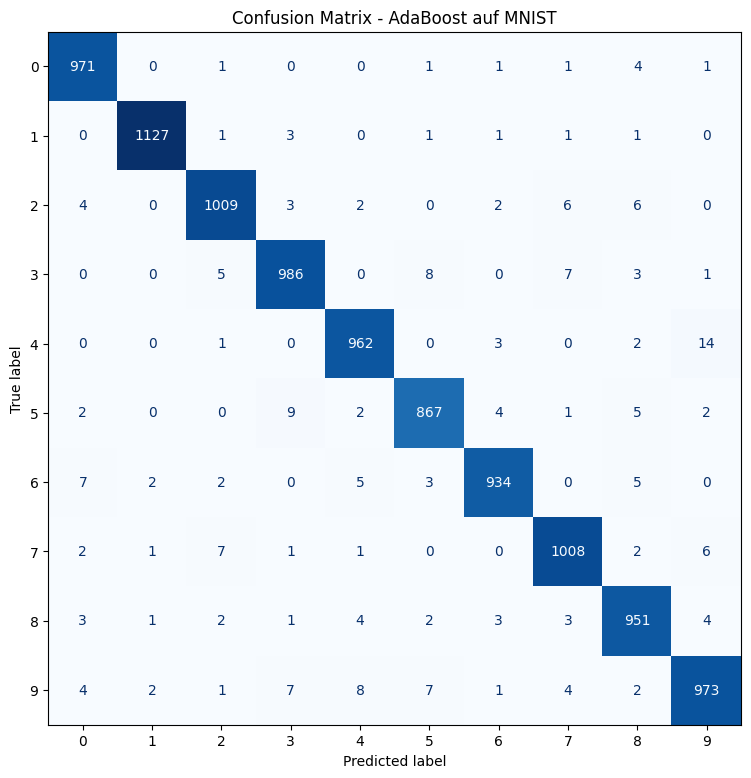

In [10]:
fig, ax = plt.subplots(figsize=(9, 9))
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_ada,
    display_labels=[str(i) for i in range(10)]
)
disp.plot(cmap="Blues", ax=ax, values_format="d", colorbar=False)
plt.title("Confusion Matrix - AdaBoost auf MNIST")
plt.show()


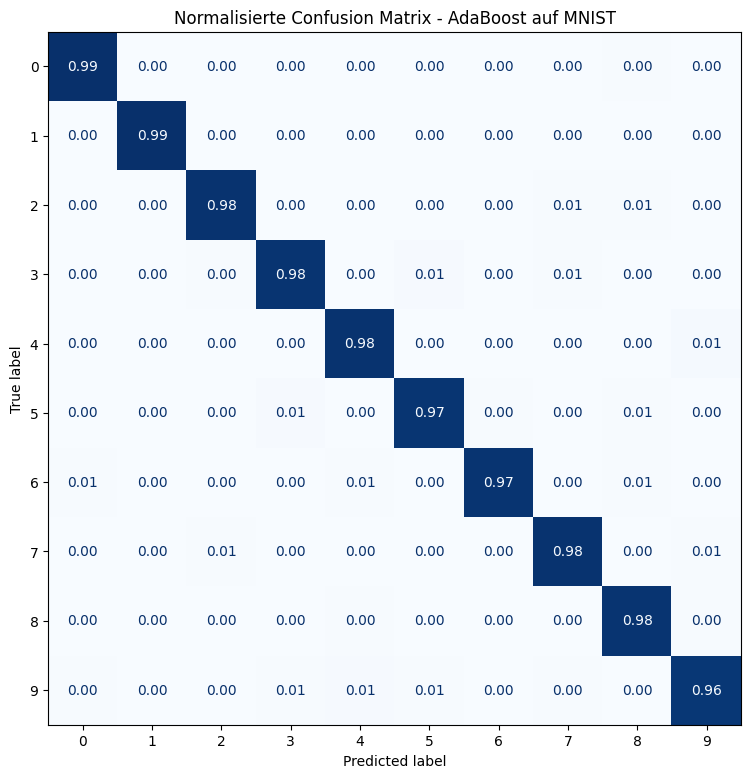

In [11]:
cm_ada_norm = confusion_matrix(y_test, y_pred_ada, normalize="true")

fig, ax = plt.subplots(figsize=(9, 9))
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_ada_norm,
    display_labels=[str(i) for i in range(10)]
)
disp.plot(cmap="Blues", ax=ax, values_format=".2f", colorbar=False)
plt.title("Normalisierte Confusion Matrix - AdaBoost auf MNIST")
plt.show()

Besonders gut erkannt werden die Ziffern 0,1,6,7 und 8. während 5 und teilweise 4 und 9 vergleichsweise schwieriger bleiben. Im vergleich zum einzelnen DecisionTree gibt es deutlich weniger Fehlklassifikationen 